In [52]:
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt

In [53]:
# Physical constants of the TOV Equations and Energy Conversions
 
import math
import numpy as np


# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions

eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m



def kg_to_MeV_c2(m_kg):

    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):

    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3

J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):

    return x * MeV_fm3_to_J_m3


def SI_to_MeV_fm3(x):

    return x * J_m3_to_MeV_fm3


In [54]:
# Numerical values
rho1 = 1.41729e14
rho2 = 2.4e14
rho3 = 2.9e14
rho4 = 3.7e14
rho5 = 4.5e14
rho6 = 5.0e14
rho7 = 5.7e14
rho8 = 6.4e14
rho9 =7.1e14
Gamma0 = 1.35692395
Gamma1 = 1.789
Gamma2 = 2.5794
Gamma3 = 3.4567
Gamma4 = 3.9887
Gamma5 = 4.788
Gamma6 = 5.1234
Gamma7 = 5.4956 
Gamma8 = 6.2345
Gamma9 = 7.0000

In [55]:
# initial arrays 


rho_breaks_cgs = np.array([rho1, rho2, rho3, rho4, rho5,rho6, rho7, rho8, rho9])
Gamma_regions = np.array([Gamma0, Gamma1, Gamma2, Gamma3, Gamma4,Gamma5, Gamma6, Gamma7, Gamma8, Gamma9])

In [56]:
# Piecewise EOS:
# Transition densities [g/cm^3]


K0 = 3.99873692e-8

N_regions = len(Gamma_regions)


if len(rho_breaks_cgs) != N_regions - 1:

    raise ValueError("For N regions you need exactly N-1 transition densities.")


if not np.all(np.diff(rho_breaks_cgs) > 0):

    raise ValueError("Transition densities must increase.")


if np.any(Gamma_regions <= 1.0):

    raise ValueError("All Gamma values must be greater than 1.")

In [57]:
# Calculate values for each regions
K_regions = np.zeros(N_regions)
a_regions = np.zeros(N_regions)


K_regions[0] = K0
a_regions[0] = 0.0

# For loop for calculating every value of Ki

for i in range(1, N_regions):
    rho_i = rho_breaks_cgs[i - 1]

    K_regions[i] = (
        K_regions[i - 1]
        * rho_i**(
            Gamma_regions[i - 1]
            - Gamma_regions[i]
        )
    )

    a_regions[i] = (
        a_regions[i - 1]
        + K_regions[i - 1]
        / (Gamma_regions[i - 1] - 1.0)
        * rho_i**(Gamma_regions[i - 1] - 1.0)

        - K_regions[i]
        / (Gamma_regions[i] - 1.0)
        * rho_i**(Gamma_regions[i] - 1.0)
    )

P_breaks_over_c2_cgs = (K_regions[:-1]* rho_breaks_cgs**Gamma_regions[:-1]) # Transition Pressures
P_breaks = (P_breaks_over_c2_cgs* 1000.0* c**2) # Converted to S I Units

def density_region(rho_cgs):
    return np.searchsorted(rho_breaks_cgs,rho_cgs,side="right") # density region identification

def pressure_region(P):
    return np.searchsorted(P_breaks,P,side="right") # pressure region identification

print("N_regions =", N_regions)
print("len(Gamma_regions) =", len(Gamma_regions))
print("len(K_regions) =", len(K_regions))
print("len(a_regions) =", len(a_regions))
print("len(rho_breaks_cgs) =", len(rho_breaks_cgs))



    
    

N_regions = 10
len(Gamma_regions) = 10
len(K_regions) = 10
len(a_regions) = 10
len(rho_breaks_cgs) = 9


In [58]:
#  New EOS that identifies its region i to calculate with relevant K and gamma i , function names are the same as before


def toy_eos(rho):
    rho = np.maximum(rho,0.0)
    rho_cgs = rho / 1000.0
    
    # Determine EOS region
    region = density_region(rho_cgs)
    K = K_regions[region]
    Gamma = Gamma_regions[region]

    P_over_c2_cgs = (K* rho_cgs**Gamma)
    P = (P_over_c2_cgs * 1000.0 * c**2)
    
    return P

#Density Value in EOS
def densityEOS(P):

    P = np.maximum(P, 0.0)

    # Find which EOS region this pressure belongs to
    region = pressure_region(P)

    K = K_regions[region]
    Gamma = Gamma_regions[region]

    # Convert P/c^2 from SI to g/cm^3
    P_over_c2_cgs = P / c**2 / 1000.0

    # Invert:
    # P/c^2 = K rho^Gamma
    rho_cgs = (
        P_over_c2_cgs / K
    )**(1.0 / Gamma)

    # g/cm^3 -> kg/m^3
    rho = rho_cgs * 1000.0

    return rho

def int_energy(P):
    P = np.maximum(P,0.0)
    rho = densityEOS(P)
    rho_cgs = rho / 1000.0

    region = density_region(rho_cgs)
    Gamma = Gamma_regions[region]
    a = a_regions[region]
    epsilon_int = (a* rho* c**2 + P / (Gamma - 1.0))
    return epsilon_int

def e_density(P):

    rho = densityEOS(P)

    epsilon_int = int_energy(P)

    return rho * c**2 + epsilon_int



In [59]:
print("Number of regions =",N_regions)
print()


for i in range(N_regions):
    print(f"Region {i}: "f"Gamma = {Gamma_regions[i]:.6f}, "f"K = {K_regions[i]:.6e}, "f"a = {a_regions[i]:.6e}")


for i in range(N_regions - 1):
    rho_i = rho_breaks_cgs[i]
    P_left = (K_regions[i]* rho_i**Gamma_regions[i])

    P_right = (K_regions[i + 1]* rho_i**Gamma_regions[i + 1])

    print(f"Boundary {i + 1}:")
    print("P_left  =",P_left)
    print("P_right =",P_right)
    print("relative difference =",abs(P_left - P_right) / P_left)
    print()

for i in range(N_regions - 1):
    rho_cgs = rho_breaks_cgs[i]

    rho_SI = (rho_cgs* 1000.0)
    P_over_c2_cgs = (K_regions[i]* rho_cgs**Gamma_regions[i])


    P_SI = (P_over_c2_cgs* 1000.0* c**2)
    E_left = ((1.0 + a_regions[i])* rho_SI * c**2+ P_SI/ (Gamma_regions[i] - 1.0))


    E_right = ((1.0 + a_regions[i + 1])* rho_SI* c**2+ P_SI/ (Gamma_regions[i + 1] - 1.0))
    print(f"Boundary {i + 1}:")
    print("relative energy difference =",abs(E_left - E_right)/ E_left)

Number of regions = 10

Region 0: Gamma = 1.356924, K = 3.998737e-08, a = 0.000000e+00
Region 1: Gamma = 1.789000, K = 3.071966e-14, a = 6.899615e-03
Region 2: Gamma = 2.579400, K = 1.322201e-25, a = 1.122158e-02
Region 3: Gamma = 3.456700, K = 2.712912e-38, a = 1.329894e-02
Region 4: Gamma = 3.988700, K = 4.821169e-46, a = 1.451014e-02
Region 5: Gamma = 4.788000, K = 9.350603e-58, a = 1.662863e-02
Region 6: Gamma = 5.123400, K = 1.098513e-62, a = 1.758899e-02
Region 7: Gamma = 5.495600, K = 3.537272e-68, a = 1.913038e-02
Region 8: Gamma = 6.234500, K = 4.058655e-79, a = 2.318784e-02
Region 9: Gamma = 7.000000, K = 1.736776e-90, a = 2.861050e-02
Boundary 1:
P_left  = 637347227599.0876
P_right = 637347227599.0875
relative difference = 1.9152874165601022e-16

Boundary 2:
P_left  = 1635363713834.382
P_right = 1635363713834.3823
relative difference = 1.492882732658729e-16

Boundary 3:
P_left  = 2664445713143.5015
P_right = 2664445713143.5015
relative difference = 0.0

Boundary 4:
P_left  =

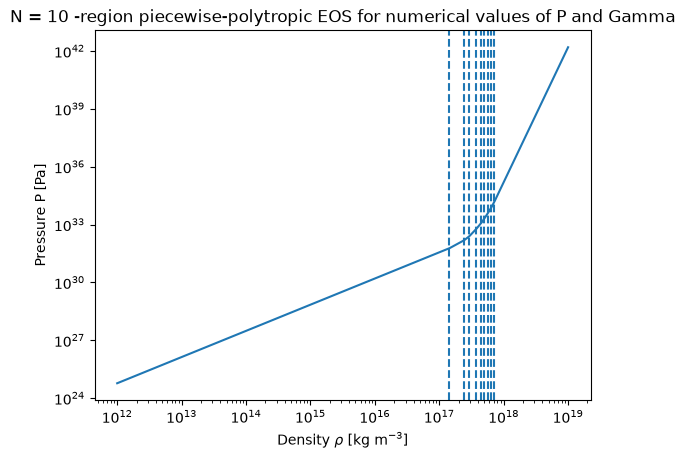

In [60]:
# Plot of EOS
rho_plot = np.logspace(12,19,1000)
P_plot = toy_eos(rho_plot)
plt.loglog(rho_plot,P_plot)

for rho_i in rho_breaks_cgs:

    plt.axvline(rho_i * 1000.0,linestyle="--")


plt.xlabel(r"Density $\rho$ [kg m$^{-3}$]")
plt.ylabel("Pressure P [Pa]")
plt.title("N = 10 -region piecewise-polytropic EOS for numerical values of P and Gamma")
plt.show()

In [61]:

# Gamma = 2.5
# rho_ref = 1.0e18      
# P_ref = 1.0e34       
# K = P_ref / rho_ref**Gamma



# def toy_eos(rho):

#     rho = np.maximum(rho, 0.0)

#     return K * rho**Gamma



# def densityEOS(P):

#     P = np.maximum(P, 0.0)

#     return (P / K)**(1.0 / Gamma)


# def int_energy(P):

#     P = np.maximum(P, 0.0)

#     return P / (Gamma - 1.0)


# # ============================================================
# # Total energy density
# # ============================================================

# def e_density(P):

#     rho = densityEOS(P)

#     epsilon_int = int_energy(P)

#     return rho * c**2 + epsilon_int
# # we have values for all necessary variants of our toy eos

In [62]:
# # piecewise polytrope equation
# # p0 region 

# Gamma0 = 1.35692395
# K0 = 3.99873692e-8
# a0 = 0.0

# # p1 region
# Gamma1 = 3.00
# rho1_cgs = 1.4172900e14

# # Formula for Gamma 1 
# K1 = K0 * rho1_cgs**(Gamma0 - Gamma1)
# # Formula for integration constant ai
# a1 = (a0 + K0 / (Gamma0 - 1.0)* rho1_cgs**(Gamma0 - 1.0) - K1 / (Gamma1 - 1.0) * rho1_cgs**(Gamma1 - 1.0))

# P1_over_c2_cgs = K0 * rho1_cgs**Gamma0
# # P in pascals
# P1 = (P1_over_c2_cgs* 1000.0* c**2)


# def toy_eos(rho):
#     rho = np.maximum(rho, 0.0)
#     rho_cgs = rho / 1000.0
#     # Calculate P/c^2 in g/cm^3

#     P_over_c2_cgs = np.where(rho_cgs < rho1_cgs,K0 * rho_cgs**Gamma0,K1 * rho_cgs**Gamma1)
#     # Convert to SI pressure [Pa]

#     P = (P_over_c2_cgs* 1000.0* c**2)
#     return P


# def densityEOS(P):
#     P = np.maximum(P, 0.0)
#     # Convert P/c^2 into g/cm^3

#     P_over_c2_cgs = (P / c**2 / 1000.0)


#     # Invert the appropriate branch
#     #if P < P1:
#     #use low-density EOS branch
#     #else:
#     #use high-density EOS branch

#     rho_cgs = np.where(P < P1,(P_over_c2_cgs / K0)**(1.0 / Gamma0),(P_over_c2_cgs / K1)**(1.0 / Gamma1))


#     # Convert back to kg/m^3

#     return rho_cgs * 1000.0


# # ============================================================
# # Internal energy density
# # ============================================================

# def int_energy(P):
#     P = np.maximum(P, 0.0)
#     rho = densityEOS(P)
    

#     low_density = rho < rho1_cgs * 1000.0
#     Gamma = np.where(low_density,Gamma0,Gamma1)
#     a = np.where(low_density,a0,a1)
#     epsilon_int = (a * rho * c**2+ P / (Gamma - 1.0))
#     return epsilon_int


# # Total energy density


# def e_density(P):


#     rho = densityEOS(P)
#     epsilon_int = int_energy(P)
#     return (rho * c**2 + epsilon_int)


# print("K0 =", K0)
# print("Gamma0 =", Gamma0)
# print("a0 =", a0)
# print()
# print("K1 =", K1)
# print("Gamma1 =", Gamma1)
# print("a1 =", a1)


# print()


# print("Transition density =",rho1_cgs,"g/cm^3")
# # Numerical value of P1
# print("Transition pressure =",P1,"Pa")


In [63]:
# TOV Equations
def tov_equations(r,y):
    m,P = y
    if r <= 0.0:
        print("TOV equations cannot be evaluated at singularity.")

    if P <= 0.0:

        return [0.0, 0.0]
    E = e_density(P)
    
    dmdr = 4.0 * np.pi * r**2 * E/ c**2
    t1 = G * E * m / (c**2 * r**2)

    t2 = 1.0 + P / E

    t3 = 1.0 + (4.0 * np.pi * r**3 * P) / (m * c**2)

    t4 = 1.0 - (2.0 * G * m) / (c**2 * r)

    dPdr = -t1 * t2 * t3 / t4
    return [dmdr, dPdr]

In [65]:
#Boundary Conditions: Sueface of the Neutron Star

# Stellar surface: P(R) = 0

r_max = 5.0e4
def surface_event(r, y):
    m, P = y

    return P

surface_event.terminal = True


surface_event.direction = -1
rho_c = 1.0e18

# ============================================================
def solve_star(rho_c,r_start=1.0e-3,r_max=5.0e4,rtol=1.0e-7,atol = [1.0e-6, 1.0e18],max_step=25.0):
    r_centre = 0.0
    m_centre = 0.0
    rho_centre = rho_c
    P_c = toy_eos(rho_c)


    # Central total energy density

    E_c = e_density(P_c)


    
    # we start numerical integration at a tiny small r expansion
    m_start = ((4.0 * np.pi / 3.0)* r_start **3 * E_c / c**2)
    # P(r_start) ≈ P_c

    P_start = P_c
    y_start = [m_start,P_start]
    # 
    solution = solve_ivp(tov_equations,t_span=(r_start,r_max),y0=y_start,events=surface_event,rtol=1.0e-7,atol = [1.0e-6, 1.0e18],max_step=50)
    if solution.t_events[0].size == 0:
        raise RuntimeError("The integration did not reach P = 0. ""Increase r_max or check the EOS.")


    R = solution.t_events[0][0]

    M = solution.y_events[0][0][0]
    P_surface = 0.0
    rho_surface = densityEOS(P_surface)
    E_surface = e_density(P_surface)


    return (solution,R,M,P_c,E_c,rho_surface,E_surface)

solution, R, M, P_c, E_c, rho_surface, E_surface = solve_star(rho_c)
print(R)
print(M)
print(P_c)
print(E_c)
print(rho_surface) # 0
print(E_surface) # 0

12340.72534421541
6.271326801472976e+30
1.5609364917292641e+35
1.1846250961938483e+35
0.0
0.0


In [66]:
# ============================================================
#Construct the complete stellar profile

# Numerical solution returned by solve_ivp

r_internal = solution.t
m_internal = solution.y[0]
P_internal = solution.y[1]

r_profile = np.concatenate(([0.0], r_internal))
m_profile = np.concatenate(([0.0], m_internal))
P_profile = np.concatenate(([P_c], P_internal))


r_profile[-1] = R
m_profile[-1] = M
P_profile[-1] = 0.0


rho_profile = densityEOS(P_profile)
epsilon_internal_profile = int_energy(P_profile)
E_profile = e_density(P_profile)



print("CENTRE")
print("------")

print("r =", r_profile[0], "m")
print("m =", m_profile[0], "kg")
print("rho =", rho_profile[0], "kg/m^3")
print("P =", P_profile[0], "Pa")
print("E =", E_profile[0], "J/m^3")


print("SURFACE")
print("-------")

print("R =", r_profile[-1] / 1000.0, "km")
print("M =", m_profile[-1] / M_sun, "M_sun")
print("rho =", rho_profile[-1], "kg/m^3")
print("P =", P_profile[-1], "Pa")

#Converting energy quantities to nuclear units


P_profile_MeV = SI_to_MeV_fm3(P_profile)
E_profile_MeV = SI_to_MeV_fm3(E_profile)
epsilon_internal_MeV = SI_to_MeV_fm3(epsilon_internal_profile)

CENTRE
------
r = 0.0 m
m = 0.0 kg
rho = 9.999999999999981e+17 kg/m^3
P = 1.5609364917292641e+35 Pa
E = 1.1846250961938483e+35 J/m^3
SURFACE
-------
R = 12.34072534421541 km
M = 3.153845319000526 M_sun
rho = 0.0 kg/m^3
P = 0.0 Pa


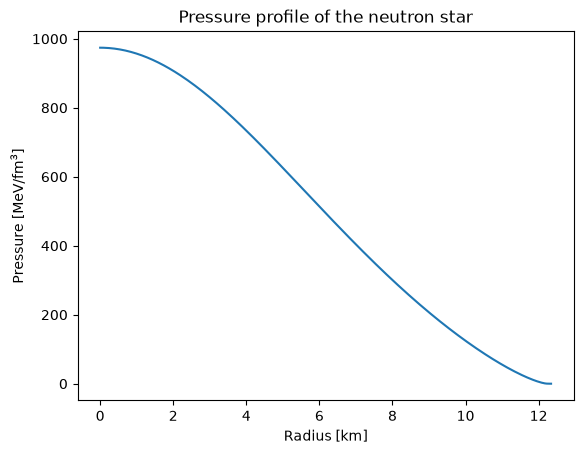

In [67]:
# Plotting the pressure profile wrt radius to surface
plt.plot(r_profile / 1000.0,P_profile_MeV)
plt.xlabel("Radius [km]")
plt.ylabel(r"Pressure [MeV/fm$^3$]")
plt.title("Pressure profile of the neutron star")
plt.show()

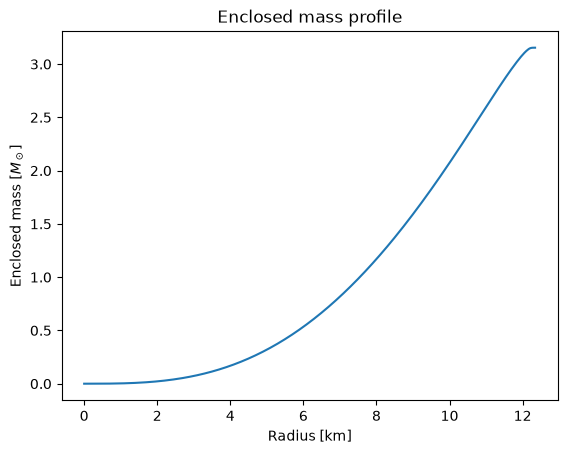

In [68]:

#Plot of enclosed mass from core to sueface
plt.plot(r_profile / 1000.0,m_profile / M_sun)
plt.xlabel("Radius [km]")
plt.ylabel(r"Enclosed mass [$M_\odot$]")
plt.title("Enclosed mass profile")
plt.show()

In [69]:

#Generate a sequence of neutron stars


rho_c_values = np.logspace(np.log10(8.0e17),np.log10(1.0e19),150)

masses = []
radii = []
successful_rho_c = []
for rho_c_trial in rho_c_values:

    try:

        (
            solution_trial,
            R_trial,
            M_trial,
            P_c_trial,
            E_c_trial,
            rho_surface_trial,
            E_surface_trial

        ) = solve_star(
            rho_c_trial
        )


        radii.append(
            R_trial / 1000.0
        )

        masses.append(
            M_trial / M_sun
        )

        successful_rho_c.append(
            rho_c_trial
        )


    except RuntimeError:

        continue
radii = np.array(radii)

masses = np.array(masses)

successful_rho_c = np.array(successful_rho_c)


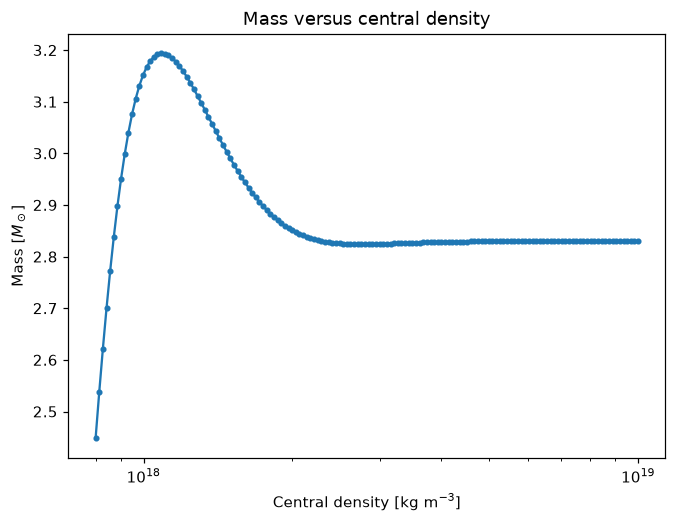

In [70]:
plt.figure(figsize=(7, 5))
plt.plot(successful_rho_c,masses,marker=".")
plt.xscale("log")
plt.xlabel(r"Central density [kg m$^{-3}$]")
plt.ylabel(r"Mass [$M_\odot$]")
plt.title("Mass versus central density")
plt.show()

In [71]:

i_max = np.argmax(masses)
M_max = masses[i_max]
R_at_Mmax = radii[i_max]
rho_c_at_Mmax = successful_rho_c[i_max]


print("Maximum mass =",M_max,"Solar Masses")
print("Radius at maximum mass =",R_at_Mmax,"km")
print("Central density at maximum mass =",rho_c_at_Mmax,"kg/m^3")

Maximum mass = 3.1938446980610924 Solar Masses
Radius at maximum mass = 12.073171235697624 km
Central density at maximum mass = 1.0854319624942845e+18 kg/m^3


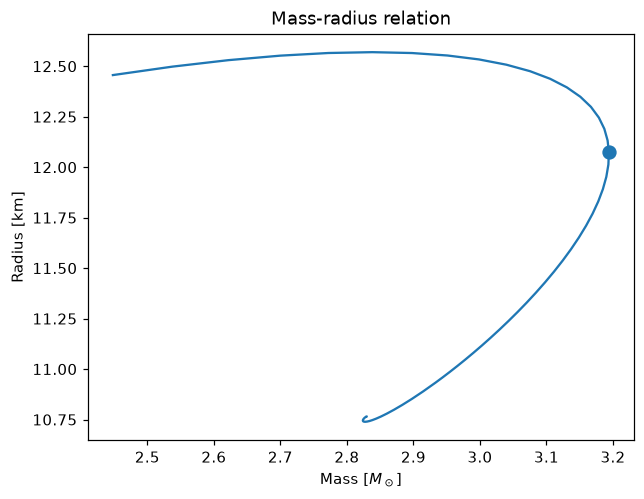

In [73]:
plt.plot(masses,radii)
 
plt.scatter(M_max,R_at_Mmax,s=70,label=(f"Maximum mass = "f"{M_max:.3f} $M_\\odot$"))
plt.xlabel(r"Mass [$M_\odot$]")

plt.ylabel("Radius [km]")
plt.title("Mass-radius relation")


plt.show()











MOST COMPACT STAR
-----------------
Maximum compactness = 0.40025388612957463
Mass = 3.084242384471309 M_sun
Radius = 11.378795826294821 km
Central density = 1.330283952196667e+18 kg/m^3


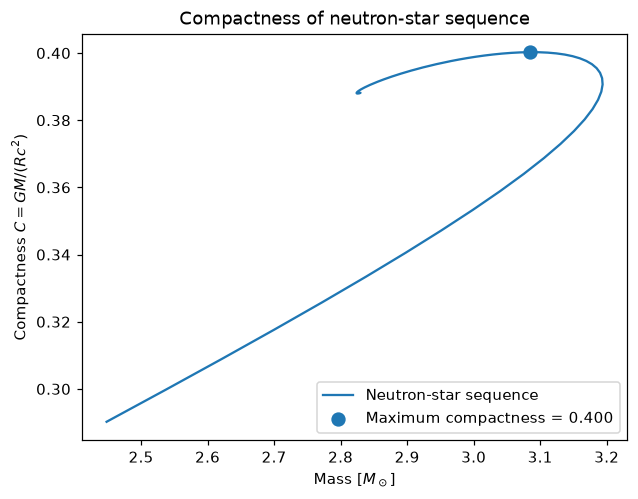

In [74]:
# Plot cof compactness C = GM/Rc^2

M_values_kg = masses * M_sun
R_values_m = radii * 1000.0

compactness = (G * M_values_kg / (R_values_m * c**2))


i_most_compact = np.argmax(compactness)

C_max = compactness[i_most_compact]
M_at_Cmax = masses[i_most_compact]
R_at_Cmax = radii[i_most_compact]
rho_c_at_Cmax = successful_rho_c[i_most_compact]



print("MOST COMPACT STAR")
print("-----------------")

print("Maximum compactness =", C_max)
print("Mass =",M_at_Cmax,"M_sun")
print("Radius =",R_at_Cmax,"km")
print("Central density =",rho_c_at_Cmax,"kg/m^3")


plt.plot(masses,compactness,label="Neutron-star sequence")


# Mark most compact star
plt.scatter(M_at_Cmax,C_max,s=70,label=(f"Maximum compactness = {C_max:.3f}"))


plt.xlabel(r"Mass [$M_\odot$]")
plt.ylabel(r"Compactness $C = GM/(Rc^2)$")

plt.title("Compactness of neutron-star sequence")
plt.legend()
plt.show()